In [293]:
import pandas as pd

In [294]:
hdi_raw = pd.read_excel('../raw_data/HDR25_Statistical_Annex_HDI_Table.xlsx')

In [295]:
hdi_raw.head()

,Unnamed: 0,Table 1. Human Development Index and its components,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,Unnamed: 10,Unnamed: 11,Unnamed: 12,Unnamed: 13,Unnamed: 14
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,SDG3,NaN,SDG4.3,NaN,SDG4.4,NaN,SDG8.5,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,Human Development Index (HDI),NaN,Life expectancy at birth,NaN,Expected years of schooling,NaN,Mean years of schooling,NaN,Gross national income (GNI) per capita,NaN,GNI per capita rank minus HDI rank,NaN,HDI rank
4,HDI rank,Country,Value,NaN,(years),NaN,(years),NaN,(years),NaN,(2021 PPP $),NaN,NaN,NaN,NaN


## Уровень человеческого развития по странам за 2023 год

In [296]:
hdi_clean = hdi_raw.copy()
filtered = hdi_clean[hdi_clean['Unnamed: 0'].notna()]
filtered = filtered[filtered['Unnamed: 0'] != 'HDI rank']
hdi_clean = filtered[['Unnamed: 0','Table 1. Human Development Index and its components','Unnamed: 2','Unnamed: 4','Unnamed: 6','Unnamed: 8','Unnamed: 10']]
hdi_clean = hdi_clean.rename(columns={
    'Unnamed: 0':'hdi_rank',
    'Table 1. Human Development Index and its components':'country',
    'Unnamed: 2':'hdi','Unnamed: 4':'life_expectancy',
    'Unnamed: 6':'expected_years_schooling',
    'Unnamed: 8':'mean_years_schooling',
    'Unnamed: 10':'gni_per_capita_ppp'})

In [297]:
hdi_clean

,hdi_rank,country,hdi,life_expectancy,expected_years_schooling,mean_years_schooling,gni_per_capita_ppp
7,1,Iceland,0.972,82.691,18.85059,13.908926,69116.93736
8,2,Norway,0.97,83.308,18.79285,13.117962,112710.0211
9,2,Switzerland,0.97,83.954,16.66753,13.949121,81948.90177
10,4,Denmark,0.962,81.933,18.70401,13.027321,76007.85669
11,5,Germany,0.959,81.378,17.309219,14.296372,64053.22124
...,...,...,...,...,...,...,...
198,188,Niger,0.419,61.183,8.30892,1.412289,1590.18796
199,190,Chad,0.416,55.069,8.34759,2.334985,1748.000992
200,191,Central African Republic,0.414,57.408,7.435768,3.989431,1099.860681
201,192,Somalia,0.404,58.816,7.486165,1.9,1474.738459


In [298]:
%pip install xlrd

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.1.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


## ВВП на душу населения

In [299]:
gdp_raw = pd.read_excel(r'../raw_data/API_NY.GDP.PCAP.PP.KD_DS2_en_excel_v2_5411.xls',header=3)
gdp_raw.head(3)

,Country Name,Country Code,Indicator Name,Indicator Code,1960,1961,1962,1963,1964,1965,...,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
0,Aruba,ABW,"GDP per capita, PPP (constant 2021 internation...",NY.GDP.PCAP.PP.KD,NaN,NaN,NaN,NaN,NaN,NaN,...,36926.113069,38213.289239,39378.228411,39754.560072,30408.827090,35207.170909,39083.461640,42783.248907,45428.002728,NaN
1,Africa Eastern and Southern,AFE,"GDP per capita, PPP (constant 2021 internation...",NY.GDP.PCAP.PP.KD,NaN,NaN,NaN,NaN,NaN,NaN,...,4210.935695,4223.188050,4229.839634,4200.531044,3978.133502,4049.969513,4098.126192,4076.224898,4099.889812,4164.679177
2,Afghanistan,AFG,"GDP per capita, PPP (constant 2021 internation...",NY.GDP.PCAP.PP.KD,NaN,NaN,NaN,NaN,NaN,NaN,...,2958.785399,2952.998916,2902.392113,2927.245144,2769.685745,2144.166570,1981.710168,1983.812620,1964.452289,NaN


In [300]:
gdp_clean = gdp_raw.drop(columns=['Indicator Name','Indicator Code'])
gdp_clean.sort_values('2025',ascending=False)[['Country Name','2015','2020','2021','2022','2023','2024','2025']].head(5).round(2)


,Country Name,2015,2020,2021,2022,2023,2024,2025
208,Singapore,109894.04,116684.21,133990.19,134828.00,130296.84,134548.76,139592.61
111,Ireland,80815.64,101793.45,116702.86,123007.48,117659.73,118833.31,131338.44
144,Luxembourg,130097.34,129865.63,136772.44,132570.83,130048.92,128475.28,127420.60
146,"Macao SAR, China",123194.07,59662.49,73374.45,59921.44,104815.20,111693.50,117098.27
200,Qatar,123070.89,103061.91,116832.57,114740.12,116159.14,111314.25,110135.70


## База данных о демократии, политических институтах, выборах, гражданских правах и свободах в разных странах

In [301]:
vdem_raw = pd.read_csv('../raw_data/V-Dem-CY-Core-v16.csv')
vdem_raw.shape

(28092, 1908)

In [302]:
vdem_clean = vdem_raw[['country_name','country_text_id','year','v2x_polyarchy','v2x_libdem','v2x_freexp_altinf']].copy()
filtered_vdem = vdem_clean[vdem_clean['year'] >= 1990].copy()
filtered_vdem = filtered_vdem.rename(columns={'country_name':'country',
                                              'country_text_id':'country_code',
                                              'v2x_polyarchy':'electoral_democracy',
                                              'v2x_libdem':'liberal_democracy',
                                              'v2x_freexp_altinf':'freedom_expression'})


In [303]:
vdem_clean.head()

,country_name,country_text_id,year,v2x_polyarchy,v2x_libdem,v2x_freexp_altinf
0,Mexico,MEX,1789,0.027,0.044,0.165
1,Mexico,MEX,1790,0.027,0.044,0.165
2,Mexico,MEX,1791,0.027,0.044,0.165
3,Mexico,MEX,1792,0.027,0.044,0.165
4,Mexico,MEX,1793,0.027,0.044,0.165


## Численность населения стран мира

In [304]:
population_raw = pd.read_excel(r'../raw_data/API_SP.POP.TOTL_DS2_en_excel_v2_2009.xls',header=3)
population_raw = population_raw.drop(columns=['Indicator Name', 'Indicator Code'])

In [305]:
population_clean = population_raw.rename(columns={'Country Name': 'country','Country Code': 'country_code'})
years = [str(year) for year in range(1990, 2026)]


In [306]:
population_clean = population_clean[['country', 'country_code'] + years]
population_clean.head()

,country,country_code,1990,1991,1992,1993,1994,1995,1996,1997,...,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
0,Aruba,ABW,62753.0,65896.0,69005.0,73685.0,77595.0,79805.0,83021.0,86301.0,...,108727.0,108735.0,108908.0,109203.0,108587.0,107700.0,107310.0,107359.0,107995.0,108785.0
1,Africa Eastern and Southern,AFE,311748681.0,320442961.0,329082707.0,338324002.0,347441809.0,356580375.0,366138524.0,375646235.0,...,623369401.0,640058741.0,657801085.0,675950189.0,694446100.0,713090928.0,731821393.0,750491370.0,769280888.0,788844284.0
2,Afghanistan,AFG,12045660.0,12238879.0,13278974.0,14943172.0,16250794.0,17065836.0,17763266.0,18452091.0,...,34700612.0,35688935.0,36743039.0,37856121.0,39068979.0,40000412.0,40578842.0,41454761.0,42647492.0,43844111.0
3,Africa Western and Central,AFW,209281291.0,214885785.0,220890339.0,226927299.0,233041347.0,239501493.0,246128722.0,252921348.0,...,428797338.0,440150152.0,451395343.0,462522286.0,473687685.0,484978794.0,496366058.0,508318102.0,520655398.0,532809933.0
4,Angola,AGO,11626360.0,12023529.0,12423712.0,12827135.0,13249764.0,13699778.0,14170973.0,14660413.0,...,29183070.0,30234839.0,31297155.0,32375632.0,33451132.0,34532429.0,35635029.0,36749906.0,37885849.0,39040039.0


## Площадь территорий стран мира в кв километрах

In [307]:
area_clean = pd.read_excel(r'../raw_data/API_AG.SRF.TOTL.K2_DS2_en_excel_v2_5981.xls',header=3)
area_clean = area_clean[['Country Name', 'Country Code', '2023']].copy()
area_clean = area_clean.rename(columns={
    'Country Name': 'country',
    'Country Code': 'country_code',
    '2023': 'area_sq_km'})

area_clean.head()

,country,country_code,area_sq_km
0,Aruba,ABW,180.0
1,Africa Eastern and Southern,AFE,15173741.5
2,Afghanistan,AFG,652870.0
3,Africa Western and Central,AFW,9166249.0
4,Angola,AGO,1246700.0


## Уровень восприятия коррупции в странах

In [308]:
cpi_raw = pd.read_excel('../raw_data/CPI2025_fixed.xlsx',header=3)

cpi_clean = cpi_raw[['Country / Territory', 'ISO3', 'Region', 'CPI 2025 score', 'Rank']].copy()
cpi_clean = cpi_clean.rename(columns={'Country / Territory':'country',
                                    'ISO3':'country_code',
                                    'CPI 2025 score':'cpi_2025',
                                    'Rank':'cpi_rank',
                                    'Region':'region'})
cpi_clean.head()

,country,country_code,region,cpi_2025,cpi_rank
0,Denmark,DNK,WE/EU,89,1
1,Finland,FIN,WE/EU,88,2
2,Singapore,SGP,AP,84,3
3,New Zealand,NZL,AP,81,4
4,Norway,NOR,WE/EU,81,4


## Всемирный индекс свободы прессы — 2025

In [309]:
press_raw = pd.read_csv('../raw_data/2025.csv',encoding='cp1252',sep=';')
press_raw.head()

,ISO,Score 2025,Rank,Political Context,Rank_Pol,Economic Context,Rank_Eco,Legal Context,Rank_Leg,Social Context,...,Country_EN,Country_ES,Country_PT,Country_AR,Country_FA,Year (N),Rank N-1,Rank evolution,Score N-1,Score evolution
0,FIN,"87,18",5,"89,93",7,"80,54",4,"87,93",7,"83,87",...,Finland,Finlandia,Finlândia,??????,??????,2025,5,0,"86,55","0,63"
1,EST,"89,46",2,"90,87",4,"79,4",5,90,3,"91,61",...,Estonia,Estonia,Estônia,???????,??????,2025,6,4,"86,44","3,02"
2,NLD,"88,64",3,"89,95",6,"83,85",2,"89,69",4,"88,05",...,Netherlands,Países Bajos,Países Baixos,??????,????,2025,4,1,"87,73","0,91"
3,SWE,"88,13",4,"90,07",5,"82,71",3,"90,02",2,"84,99",...,Sweden,Suecia,Suécia,??????,????,2025,3,-1,"88,32","-0,19"
4,LTU,"82,27",14,"80,76",17,"68,84",15,"83,23",18,"85,39",...,Lithuania,Lituania,Lituânia,????????,???????,2025,13,-1,"81,73","0,54"


In [310]:
press_clean = press_raw[['Country_EN','ISO','Score 2025','Rank','Political Context','Economic Context',
        'Legal Context','Social Context','Safety']].copy()
press_clean = press_clean.rename(columns={
    'Country_EN': 'country',
    'ISO': 'country_code',
    'Score 2025': 'press_freedom',
    'Rank': 'press_rank',
    'Political Context': 'press_political',
    'Economic Context': 'press_economic',
    'Legal Context': 'press_legal',
    'Social Context': 'press_social',
    'Safety': 'press_safety'})
press_clean.head()

,country,country_code,press_freedom,press_rank,press_political,press_economic,press_legal,press_social,press_safety
0,Finland,FIN,"87,18",5,"89,93","80,54","87,93","83,87","93,65"
1,Estonia,EST,"89,46",2,"90,87","79,4",90,"91,61","95,41"
2,Netherlands,NLD,"88,64",3,"89,95","83,85","89,69","88,05","91,64"
3,Sweden,SWE,"88,13",4,"90,07","82,71","90,02","84,99","92,86"
4,Lithuania,LTU,"82,27",14,"80,76","68,84","83,23","85,39","93,12"


In [311]:
cols = ['press_freedom','press_political','press_economic','press_legal','press_social','press_safety']

for col in cols:
    press_clean[col] = pd.to_numeric(press_clean[col].str.replace(',', '.', regex=False),errors='coerce')


In [312]:
press_clean.sort_values('press_political',ascending=False).head()

,country,country_code,press_freedom,press_rank,press_political,press_economic,press_legal,press_social,press_safety
10,Norway,NOR,92.31,1,96.22,87.32,91.96,90.03,96.03
6,Ireland,IRL,86.92,7,91.30,78.77,81.49,87.25,95.80
5,Denmark,DNK,86.93,6,91.13,78.46,86.78,83.85,94.43
1,Estonia,EST,89.46,2,90.87,79.40,90.00,91.61,95.41
3,Sweden,SWE,88.13,4,90.07,82.71,90.02,84.99,92.86


In [313]:
%pip install pycountry

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.1.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


## Политические заключенные в странах (0 - много (50 или более), 1 - есть, но не много ( от 0 до 49) , 2 - отсутствуют или данных нет)

In [314]:
political_prisoners_raw = pd.read_csv('../raw_data/qogdata_21_10_2026.csv',sep=';',decimal=',')

political_prisoners_clean = political_prisoners_raw[['cname', 'ccodealp', 'year', 'ciri_polpris']].copy()

political_prisoners_clean = political_prisoners_clean.rename(columns={
    'cname': 'country','ccodealp': 'country_code',
    'ciri_polpris': 'political_imprisonment'})

political_prisoners_clean = political_prisoners_clean[political_prisoners_clean['year'] >= 1990].copy()
political_prisoners_clean.head()

,country,country_code,year,political_imprisonment
9,Afghanistan,AFG,1990,0.0
10,Afghanistan,AFG,1991,0.0
11,Afghanistan,AFG,1996,0.0
12,Afghanistan,AFG,1997,0.0
13,Afghanistan,AFG,1998,0.0


In [315]:
print('Строк:', len(political_prisoners_clean))
print('Стран:', political_prisoners_clean['country_code'].nunique())
print('Годы:', political_prisoners_clean['year'].min(),
      '-', political_prisoners_clean['year'].max())

print('\nПропуски:')
print(political_prisoners_clean.isna().sum())

print('\nЗначения показателя:')
print(political_prisoners_clean['political_imprisonment'].value_counts(dropna=False))

Строк: 5865
Стран: 198
Годы: 1990 - 2022

Пропуски:
country                   0
country_code              0
year                      0
political_imprisonment    0
dtype: int64

Значения показателя:
political_imprisonment
2.0    2969
0.0    1496
1.0    1400
Name: count, dtype: int64


In [316]:
political_prisoners_clean.duplicated(subset=['country_code', 'year']).sum()

np.int64(0)

# Объeдинение таблиц

In [317]:
hdi_clean.head()


,hdi_rank,country,hdi,life_expectancy,expected_years_schooling,mean_years_schooling,gni_per_capita_ppp
7,1,Iceland,0.972,82.691,18.85059,13.908926,69116.93736
8,2,Norway,0.97,83.308,18.79285,13.117962,112710.0211
9,2,Switzerland,0.97,83.954,16.66753,13.949121,81948.90177
10,4,Denmark,0.962,81.933,18.70401,13.027321,76007.85669
11,5,Germany,0.959,81.378,17.309219,14.296372,64053.22124


In [318]:
gdp_clean.head()

,Country Name,Country Code,1960,1961,1962,1963,1964,1965,1966,1967,...,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
0,Aruba,ABW,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,36926.113069,38213.289239,39378.228411,39754.560072,30408.827090,35207.170909,39083.461640,42783.248907,45428.002728,NaN
1,Africa Eastern and Southern,AFE,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,4210.935695,4223.188050,4229.839634,4200.531044,3978.133502,4049.969513,4098.126192,4076.224898,4099.889812,4164.679177
2,Afghanistan,AFG,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,2958.785399,2952.998916,2902.392113,2927.245144,2769.685745,2144.166570,1981.710168,1983.812620,1964.452289,NaN
3,Africa Western and Central,AFW,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,6034.826989,6009.516114,6026.527572,6070.284769,5698.766702,5702.134886,5818.483224,5886.796636,6009.084662,6139.587294
4,Angola,AGO,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,10963.996789,10565.167648,10154.838923,9712.979449,8904.949006,8720.187687,8750.993630,8597.538788,8752.797471,8760.190820


In [319]:
filtered_vdem.head(5)

,country,country_code,year,electoral_democracy,liberal_democracy,freedom_expression
201,Mexico,MEX,1990,0.388,0.186,0.586
202,Mexico,MEX,1991,0.410,0.196,0.605
203,Mexico,MEX,1992,0.438,0.208,0.605
204,Mexico,MEX,1993,0.455,0.215,0.635
205,Mexico,MEX,1994,0.467,0.260,0.671


In [320]:
population_clean.head(5)

,country,country_code,1990,1991,1992,1993,1994,1995,1996,1997,...,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
0,Aruba,ABW,62753.0,65896.0,69005.0,73685.0,77595.0,79805.0,83021.0,86301.0,...,108727.0,108735.0,108908.0,109203.0,108587.0,107700.0,107310.0,107359.0,107995.0,108785.0
1,Africa Eastern and Southern,AFE,311748681.0,320442961.0,329082707.0,338324002.0,347441809.0,356580375.0,366138524.0,375646235.0,...,623369401.0,640058741.0,657801085.0,675950189.0,694446100.0,713090928.0,731821393.0,750491370.0,769280888.0,788844284.0
2,Afghanistan,AFG,12045660.0,12238879.0,13278974.0,14943172.0,16250794.0,17065836.0,17763266.0,18452091.0,...,34700612.0,35688935.0,36743039.0,37856121.0,39068979.0,40000412.0,40578842.0,41454761.0,42647492.0,43844111.0
3,Africa Western and Central,AFW,209281291.0,214885785.0,220890339.0,226927299.0,233041347.0,239501493.0,246128722.0,252921348.0,...,428797338.0,440150152.0,451395343.0,462522286.0,473687685.0,484978794.0,496366058.0,508318102.0,520655398.0,532809933.0
4,Angola,AGO,11626360.0,12023529.0,12423712.0,12827135.0,13249764.0,13699778.0,14170973.0,14660413.0,...,29183070.0,30234839.0,31297155.0,32375632.0,33451132.0,34532429.0,35635029.0,36749906.0,37885849.0,39040039.0


In [321]:
area_clean.head(5)

,country,country_code,area_sq_km
0,Aruba,ABW,180.0
1,Africa Eastern and Southern,AFE,15173741.5
2,Afghanistan,AFG,652870.0
3,Africa Western and Central,AFW,9166249.0
4,Angola,AGO,1246700.0


In [322]:
cpi_clean.head(5)

,country,country_code,region,cpi_2025,cpi_rank
0,Denmark,DNK,WE/EU,89,1
1,Finland,FIN,WE/EU,88,2
2,Singapore,SGP,AP,84,3
3,New Zealand,NZL,AP,81,4
4,Norway,NOR,WE/EU,81,4


In [323]:
press_clean.head(5)

,country,country_code,press_freedom,press_rank,press_political,press_economic,press_legal,press_social,press_safety
0,Finland,FIN,87.18,5,89.93,80.54,87.93,83.87,93.65
1,Estonia,EST,89.46,2,90.87,79.40,90.00,91.61,95.41
2,Netherlands,NLD,88.64,3,89.95,83.85,89.69,88.05,91.64
3,Sweden,SWE,88.13,4,90.07,82.71,90.02,84.99,92.86
4,Lithuania,LTU,82.27,14,80.76,68.84,83.23,85.39,93.12


In [324]:
political_prisoners_clean.head(5)

,country,country_code,year,political_imprisonment
9,Afghanistan,AFG,1990,0.0
10,Afghanistan,AFG,1991,0.0
11,Afghanistan,AFG,1996,0.0
12,Afghanistan,AFG,1997,0.0
13,Afghanistan,AFG,1998,0.0


In [325]:
population_final = population_clean[population_clean['2025'].notna()][['country_code','country','2025']]
population_final = population_final.rename(columns={'2025':'population_2025'})
population_final.head(5)

,country_code,country,population_2025
0,ABW,Aruba,108785.0
1,AFE,Africa Eastern and Southern,788844284.0
2,AFG,Afghanistan,43844111.0
3,AFW,Africa Western and Central,532809933.0
4,AGO,Angola,39040039.0


In [326]:
area_clean = area_clean[['country_code','country','area_sq_km']]
area_clean.head(5)

,country_code,country,area_sq_km
0,ABW,Aruba,180.0
1,AFE,Africa Eastern and Southern,15173741.5
2,AFG,Afghanistan,652870.0
3,AFW,Africa Western and Central,9166249.0
4,AGO,Angola,1246700.0


In [327]:
countries_final = population_final.merge(area_clean[['country_code','area_sq_km']],on=['country_code'],how='left')
countries_final.head(5)

,country_code,country,population_2025,area_sq_km
0,ABW,Aruba,108785.0,180.0
1,AFE,Africa Eastern and Southern,788844284.0,15173741.5
2,AFG,Afghanistan,43844111.0,652870.0
3,AFW,Africa Western and Central,532809933.0,9166249.0
4,AGO,Angola,39040039.0,1246700.0


In [328]:
def to_iso3_1(code):
    country = pycountry.countries.get(name=code)
    return country.alpha_3 if country else None

In [329]:
import pycountry

In [330]:
hdi_clean['country_code'] = hdi_clean['country'].apply(to_iso3_1)
hdi_clean = hdi_clean[[
    'country_code','country','hdi_rank','hdi','life_expectancy','expected_years_schooling','mean_years_schooling','gni_per_capita_ppp']]
hdi_clean.head()


,country_code,country,hdi_rank,hdi,life_expectancy,expected_years_schooling,mean_years_schooling,gni_per_capita_ppp
7,ISL,Iceland,1,0.972,82.691,18.85059,13.908926,69116.93736
8,NOR,Norway,2,0.97,83.308,18.79285,13.117962,112710.0211
9,CHE,Switzerland,2,0.97,83.954,16.66753,13.949121,81948.90177
10,DNK,Denmark,4,0.962,81.933,18.70401,13.027321,76007.85669
11,DEU,Germany,5,0.959,81.378,17.309219,14.296372,64053.22124


In [331]:
filtered = hdi_clean[hdi_clean['country_code'].isna()]
filtered.head()

,country_code,country,hdi_rank,hdi,life_expectancy,expected_years_schooling,mean_years_schooling,gni_per_capita_ppp
14,NaN,"Hong Kong, China (SAR)",8,0.955,85.511,16.895861,12.35,69435.75706
26,NaN,Korea (Republic of),20,0.937,84.329,16.618641,12.722199,49726.45327
82,NaN,Iran (Islamic Republic of),75,0.799,77.654,13.968331,10.846712,16095.77169
93,NaN,Moldova (Republic of),86,0.785,71.198,14.638568,11.83,15866.54207
115,NaN,Bolivia (Plurinational State of),108,0.733,68.581,15.61065,10.021223,9445.244868


In [332]:
country_codes_fix = {
    'Tanzania (United Republic of)':'TZA',
    'Moldova (Republic of)':'MDA',
    'Iran (Islamic Republic of)':'IRN',
    'Venezuela (Bolivarian Republic of)':'VEN',
    'Congo (Democratic Republic of the)':'COD',
    'Korea (Republic of)':'KOR',
    'Micronesia (Federated States of)':'FSM',
    'Hong Kong, China (SAR)':'HKG',
    'Bolivia (Plurinational State of)':'BOL',
    'Eswatini (Kingdom of)':'SWZ'}


In [333]:
hdi_clean['country_code'] = hdi_clean['country_code'].fillna(hdi_clean['country'].map(country_codes_fix))
hdi_clean.head()

,country_code,country,hdi_rank,hdi,life_expectancy,expected_years_schooling,mean_years_schooling,gni_per_capita_ppp
7,ISL,Iceland,1,0.972,82.691,18.85059,13.908926,69116.93736
8,NOR,Norway,2,0.97,83.308,18.79285,13.117962,112710.0211
9,CHE,Switzerland,2,0.97,83.954,16.66753,13.949121,81948.90177
10,DNK,Denmark,4,0.962,81.933,18.70401,13.027321,76007.85669
11,DEU,Germany,5,0.959,81.378,17.309219,14.296372,64053.22124


In [334]:
hdi_clean.duplicated(subset=['country_code']).sum()

np.int64(0)

In [335]:
numeric_cols = ['hdi_rank','hdi','life_expectancy','expected_years_schooling','mean_years_schooling','gni_per_capita_ppp']
hdi_clean[numeric_cols] = hdi_clean[numeric_cols].apply(pd.to_numeric, errors='coerce')


In [336]:
countries_final = countries_final.merge(hdi_clean[['country_code','hdi']],on='country_code',how='left')
countries_final.head()

,country_code,country,population_2025,area_sq_km,hdi
0,ABW,Aruba,108785.0,180.0,NaN
1,AFE,Africa Eastern and Southern,788844284.0,15173741.5,NaN
2,AFG,Afghanistan,43844111.0,652870.0,0.496
3,AFW,Africa Western and Central,532809933.0,9166249.0,NaN
4,AGO,Angola,39040039.0,1246700.0,0.616


In [337]:
gdp_clean = gdp_clean.rename(columns={'Country Name':'country','Country Code':'country_code'})
gdp_clean = gdp_clean.rename(columns={'2023':'gdp_per_capita_ppp_2023'})

In [338]:
countries_final = countries_final.merge(gdp_clean[['country_code','gdp_per_capita_ppp_2023']],on='country_code',how='left')

In [339]:
filtered_vdem.tail()

,country,country_code,year,electoral_democracy,liberal_democracy,freedom_expression
26688,Zanzibar,ZZB,2021,0.279,0.227,0.503
26689,Zanzibar,ZZB,2022,0.289,0.236,0.521
26690,Zanzibar,ZZB,2023,0.291,0.235,0.535
26691,Zanzibar,ZZB,2024,0.288,0.247,0.502
26692,Zanzibar,ZZB,2025,0.309,0.253,0.540


In [340]:
vdem_2025 = (filtered_vdem[filtered_vdem['year'] == 2025]).copy()
vdem_2025.head()

,country,country_code,year,electoral_democracy,liberal_democracy,freedom_expression
236,Mexico,MEX,2025,0.469,0.221,0.619
362,Suriname,SUR,2025,0.781,0.626,0.891
599,Sweden,SWE,2025,0.889,0.853,0.946
827,Switzerland,CHE,2025,0.882,0.843,0.967
951,Ghana,GHA,2025,0.711,0.606,0.896


In [341]:
countries_final = countries_final.merge(vdem_2025[[
    'country_code','electoral_democracy','liberal_democracy','freedom_expression']],on='country_code',how='left')


In [342]:
countries_final = countries_final.rename(columns={
    'hdi':'hdi_2023',
    'electoral_democracy': 'electoral_democracy_2025',
    'liberal_democracy': 'liberal_democracy_2025',
    'freedom_expression': 'freedom_expression_2025'
})

In [343]:
countries_final['gdp_per_capita_ppp_2023'] = (countries_final['gdp_per_capita_ppp_2023']).round(2)
countries_final.head()

,country_code,country,population_2025,area_sq_km,hdi_2023,gdp_per_capita_ppp_2023,electoral_democracy_2025,liberal_democracy_2025,freedom_expression_2025
0,ABW,Aruba,108785.0,180.0,NaN,42783.25,NaN,NaN,NaN
1,AFE,Africa Eastern and Southern,788844284.0,15173741.5,NaN,4076.22,NaN,NaN,NaN
2,AFG,Afghanistan,43844111.0,652870.0,0.496,1983.81,0.069,0.018,0.022
3,AFW,Africa Western and Central,532809933.0,9166249.0,NaN,5886.80,NaN,NaN,NaN
4,AGO,Angola,39040039.0,1246700.0,0.616,8597.54,0.344,0.163,0.497


In [344]:
countries_final = countries_final.merge(cpi_clean[['country_code','cpi_2025']],on='country_code',how='left')

In [345]:
countries_final = countries_final.merge(press_clean[['country_code','press_political']],on='country_code',how='left')

In [346]:
political_prisoners_clean_2022 = political_prisoners_clean[political_prisoners_clean['year'] == 2022]
countries_final = countries_final.merge(political_prisoners_clean_2022[['country_code','political_imprisonment']],on='country_code',how='left')

In [347]:
countries_final.sort_values(['hdi_2023','gdp_per_capita_ppp_2023'],ascending=False)

,country_code,country,population_2025,area_sq_km,hdi_2023,gdp_per_capita_ppp_2023,electoral_democracy_2025,liberal_democracy_2025,freedom_expression_2025,cpi_2025,press_political,political_imprisonment
113,ISL,Iceland,392404.0,103000.0,0.972,69268.12,0.807,0.720,0.846,77.0,82.24,2.0
176,NOR,Norway,5610870.0,624500.0,0.970,94364.96,0.890,0.847,0.953,81.0,96.22,2.0
37,CHE,Switzerland,9092436.0,41290.7,0.970,85383.36,0.882,0.843,0.967,80.0,85.70,2.0
58,DNK,Denmark,6009169.0,42920.0,0.962,68993.90,0.913,0.884,0.980,89.0,91.13,2.0
55,DEU,Germany,83491249.0,357680.0,0.959,63140.19,0.828,0.782,0.914,77.0,84.87,2.0
...,...,...,...,...,...,...,...,...,...,...,...,...
171,NCL,New Caledonia,295333.0,18576.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
192,PRK,"Korea, Dem. People's Rep.",26571036.0,120540.0,NaN,NaN,0.083,0.014,0.013,15.0,12.18,0.0
198,PYF,French Polynesia,282465.0,3471.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
254,VGB,British Virgin Islands,39732.0,151.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [348]:
filtered_country = countries_final[countries_final['country'] == 'China']
filtered_country

,country_code,country,population_2025,area_sq_km,hdi_2023,gdp_per_capita_ppp_2023,electoral_democracy_2025,liberal_democracy_2025,freedom_expression_2025,cpi_2025,press_political,political_imprisonment
40,CHN,China,1.406585e+09,9562910.0,0.797,22687.25,0.072,0.039,0.045,43.0,9.78,0.0


In [349]:
countries_final['hdi_2023'].notna().sum()

np.int64(193)

## Итоговая таблица стран, отсортированная по HDI

In [350]:
countries_report = (countries_final.dropna(subset=['hdi_2023','electoral_democracy_2025','cpi_2025','press_political','political_imprisonment'],how='all')
    .sort_values('hdi_2023', ascending=False)
    .reset_index(drop=True)
    .copy())
countries_report.head()

,country_code,country,population_2025,area_sq_km,hdi_2023,gdp_per_capita_ppp_2023,electoral_democracy_2025,liberal_democracy_2025,freedom_expression_2025,cpi_2025,press_political,political_imprisonment
0,ISL,Iceland,392404.0,103000.0,0.972,69268.12,0.807,0.720,0.846,77.0,82.24,2.0
1,NOR,Norway,5610870.0,624500.0,0.970,94364.96,0.890,0.847,0.953,81.0,96.22,2.0
2,CHE,Switzerland,9092436.0,41290.7,0.970,85383.36,0.882,0.843,0.967,80.0,85.70,2.0
3,DNK,Denmark,6009169.0,42920.0,0.962,68993.90,0.913,0.884,0.980,89.0,91.13,2.0
4,DEU,Germany,83491249.0,357680.0,0.959,63140.19,0.828,0.782,0.914,77.0,84.87,2.0


In [351]:
countries_report.shape

(197, 12)

## Выгрузка отчета countries_report в папку processed_data

In [352]:
from pathlib import Path

Path('processed_data').mkdir(exist_ok=True)

countries_report.to_csv('processed_data/countries_report.csv',index=False,encoding='utf-8-sig')

## Проверка данных таблицы countries_final

In [353]:
countries_final = countries_final.dropna(subset=['hdi_2023','electoral_democracy_2025','cpi_2025','press_political','political_imprisonment'],how='all')

In [354]:
countries_final[['hdi_2023', 'electoral_democracy_2025', 'cpi_2025', 'press_political']].isna().all(axis=1).sum()

np.int64(1)

In [355]:
countries_final = countries_final[countries_final['country_code'] != 'CSS']
countries_final[~countries_final['country_code'].isin([c.alpha_3 for c in pycountry.countries])][['country_code', 'country']]


,country_code,country
260,XKX,Kosovo


In [356]:
countries_final.isna().sum()

country_code                 0
country                      0
population_2025              0
area_sq_km                   1
hdi_2023                     3
gdp_per_capita_ppp_2023      9
electoral_democracy_2025    21
liberal_democracy_2025      21
freedom_expression_2025     21
cpi_2025                    16
press_political             19
political_imprisonment       4
dtype: int64

In [357]:
countries_final = countries_final.reset_index(drop=True)
countries_final.sort_values('hdi_2023',ascending=False).head()

,country_code,country,population_2025,area_sq_km,hdi_2023,gdp_per_capita_ppp_2023,electoral_democracy_2025,liberal_democracy_2025,freedom_expression_2025,cpi_2025,press_political,political_imprisonment
82,ISL,Iceland,392404.0,103000.0,0.972,69268.12,0.807,0.720,0.846,77.0,82.24,2.0
130,NOR,Norway,5610870.0,624500.0,0.970,94364.96,0.890,0.847,0.953,81.0,96.22,2.0
30,CHE,Switzerland,9092436.0,41290.7,0.970,85383.36,0.882,0.843,0.967,80.0,85.70,2.0
47,DNK,Denmark,6009169.0,42920.0,0.962,68993.90,0.913,0.884,0.980,89.0,91.13,2.0
44,DEU,Germany,83491249.0,357680.0,0.959,63140.19,0.828,0.782,0.914,77.0,84.87,2.0


In [358]:
countries_final.select_dtypes(include='number').corr()

,population_2025,area_sq_km,hdi_2023,gdp_per_capita_ppp_2023,electoral_democracy_2025,liberal_democracy_2025,freedom_expression_2025,cpi_2025,press_political,political_imprisonment
population_2025,1.000000,0.401874,-0.015997,-0.051289,-0.121701,-0.113723,-0.139954,-0.049500,-0.188213,-0.183165
area_sq_km,0.401874,1.000000,0.098906,0.089775,-0.021849,-0.017792,-0.072936,0.000797,-0.044215,-0.145120
hdi_2023,-0.015997,0.098906,1.000000,0.794569,0.534107,0.582786,0.302957,0.718870,0.423471,0.298577
gdp_per_capita_ppp_2023,-0.051289,0.089775,0.794569,1.000000,0.411370,0.492523,0.217341,0.744695,0.447864,0.258359
electoral_democracy_2025,-0.121701,-0.021849,0.534107,0.411370,1.000000,0.979234,0.898551,0.673658,0.805017,0.689831
liberal_democracy_2025,-0.113723,-0.017792,0.582786,0.492523,0.979234,1.000000,0.867700,0.748468,0.823252,0.678848
freedom_expression_2025,-0.139954,-0.072936,0.302957,0.217341,0.898551,0.867700,1.000000,0.514151,0.790165,0.684751
cpi_2025,-0.049500,0.000797,0.718870,0.744695,0.673658,0.748468,0.514151,1.000000,0.648662,0.487100
press_political,-0.188213,-0.044215,0.423471,0.447864,0.805017,0.823252,0.790165,0.648662,1.000000,0.633831
political_imprisonment,-0.183165,-0.145120,0.298577,0.258359,0.689831,0.678848,0.684751,0.487100,0.633831,1.000000


## Гипотеза № 1 (Связь уровня развития человека с наличием политзаключенных)

In [359]:
hdi_by_imprisonment = countries_final.groupby('political_imprisonment').agg(mean_hdi=('hdi_2023','mean'),count_hdi=('hdi_2023','count'),median_hdi=('hdi_2023','median'))
hdi_by_imprisonment

,mean_hdi,count_hdi,median_hdi
political_imprisonment,,,
0.0,0.691825,57,0.7200
1.0,0.626389,18,0.5995
2.0,0.783696,115,0.8070


In [360]:
filtered_political_imprisonment_0 = countries_final[countries_final['political_imprisonment'] == 0]
filtered_political_imprisonment_0 = filtered_political_imprisonment_0.sort_values('hdi_2023',ascending=False)
filtered_political_imprisonment_0.head(10)

,country_code,country,population_2025,area_sq_km,hdi_2023,gdp_per_capita_ppp_2023,electoral_democracy_2025,liberal_democracy_2025,freedom_expression_2025,cpi_2025,press_political,political_imprisonment
4,ARE,United Arab Emirates,11513149.0,98647.9,0.940,70239.83,0.104,0.077,0.063,69.0,17.23,0.0
184,USA,United States,341784857.0,9831510.0,0.938,74351.67,0.735,0.571,0.729,64.0,62.38,0.0
83,ISR,Israel,10122800.0,22070.0,0.919,47671.25,0.694,0.588,0.822,62.0,51.88,0.0
150,SAU,Saudi Arabia,36973555.0,2149690.0,0.900,64481.84,0.016,0.047,0.092,57.0,23.83,0.0
17,BHR,Bahrain,1600366.0,800.0,0.899,57819.91,0.139,0.062,0.172,50.0,25.38,0.0
178,TUR,Turkiye,85878556.0,785350.0,0.853,35069.17,0.293,0.110,0.179,31.0,19.69,0.0
95,KWT,Kuwait,4865298.0,17820.0,0.852,47790.19,0.138,0.127,0.532,46.0,33.04,0.0
88,KAZ,Kazakhstan,20843754.0,2724902.0,0.837,34703.23,0.259,0.131,0.329,38.0,29.21,0.0
148,RUS,Russian Federation,143513328.0,17125190.0,0.832,39881.45,0.170,0.056,0.080,22.0,12.05,0.0
20,BLR,Belarus,9085991.0,207629.0,0.824,27782.44,0.163,0.038,0.025,31.0,13.27,0.0


In [361]:
filtered_political_imprisonment_2 = countries_final[countries_final['political_imprisonment'] == 2]
filtered_political_imprisonment_2 = filtered_political_imprisonment_2.sort_values('hdi_2023')
filtered_political_imprisonment_2.head(10)

,country_code,country,population_2025,area_sq_km,hdi_2023,gdp_per_capita_ppp_2023,electoral_democracy_2025,liberal_democracy_2025,freedom_expression_2025,cpi_2025,press_political,political_imprisonment
28,CAF,Central African Republic,5513282.0,622980.0,0.414,1132.68,0.293,0.102,0.613,24.0,50.680,2.0
126,NER,Niger,27917831.0,1267000.0,0.419,1712.97,0.227,0.177,0.756,31.0,49.710,2.0
14,BFA,Burkina Faso,24074580.0,274200.0,0.459,2486.21,0.134,0.103,0.261,40.0,41.900,2.0
120,MOZ,Mozambique,35631653.0,799380.0,0.493,1512.67,0.279,0.175,0.518,21.0,39.650,2.0
98,LBR,Liberia,5731206.0,111370.0,0.510,1616.92,0.597,0.417,0.836,28.0,56.430,2.0
66,GNB,Guinea-Bissau,2249515.0,36125.0,0.514,2660.81,0.252,0.095,0.552,21.0,41.274,2.0
123,MWI,Malawi,22216120.0,118484.0,0.517,1649.30,0.557,0.462,0.754,34.0,47.080,2.0
65,GMB,"Gambia, The",2822093.0,11300.0,0.524,2963.60,0.641,0.522,0.814,37.0,59.100,2.0
103,LSO,Lesotho,2363325.0,30360.0,0.550,2592.46,0.661,0.512,0.728,37.0,40.550,2.0
75,HTI,Haiti,11906095.0,27750.0,0.554,2939.12,0.238,0.098,0.799,16.0,48.580,2.0


## Гипотеза № 2 связь индекса развития человека с уровнем восприятия коррупции

In [362]:
countries_final['corruption_group'] = pd.cut(countries_final['cpi_2025'],
    bins=[0, 30, 50, 70, 100],labels=['Very high', 'High', 'Moderate', 'Low'],include_lowest=True,right=False)

In [363]:
countries_final.head()

,country_code,country,population_2025,area_sq_km,hdi_2023,gdp_per_capita_ppp_2023,electoral_democracy_2025,liberal_democracy_2025,freedom_expression_2025,cpi_2025,press_political,political_imprisonment,corruption_group
0,AFG,Afghanistan,43844111.0,652870.0,0.496,1983.81,0.069,0.018,0.022,16.0,17.78,0.0,Very high
1,AGO,Angola,39040039.0,1246700.0,0.616,8597.54,0.344,0.163,0.497,32.0,38.68,0.0,High
2,ALB,Albania,2349580.0,28750.0,0.810,20501.65,0.484,0.382,0.673,39.0,38.62,2.0,High
3,AND,Andorra,82904.0,468.0,0.913,64631.30,NaN,NaN,NaN,NaN,56.13,2.0,NaN
4,ARE,United Arab Emirates,11513149.0,98647.9,0.940,70239.83,0.104,0.077,0.063,69.0,17.23,0.0,Moderate


In [364]:
hdi_by_corruption = countries_final.groupby('corruption_group').agg(
    mean_hdi=('hdi_2023','mean'),median_hdi=('hdi_2023','median'),count_hdi=('hdi_2023','count'))
hdi_by_corruption.head()

,mean_hdi,median_hdi,count_hdi
corruption_group,,,
Very high,0.601702,0.5980,47
High,0.714459,0.7505,74
Moderate,0.852842,0.8875,38
Low,0.931900,0.9485,20


## Таблица рейтингов

In [365]:
country_ranking = countries_final[
    ['country_code', 'country', 'hdi_2023', 'cpi_2025',
     'press_political', 'electoral_democracy_2025',
     'political_imprisonment']].copy()
country_ranking

,country_code,country,hdi_2023,cpi_2025,press_political,electoral_democracy_2025,political_imprisonment
0,AFG,Afghanistan,0.496,16.0,17.78,0.069,0.0
1,AGO,Angola,0.616,32.0,38.68,0.344,0.0
2,ALB,Albania,0.810,39.0,38.62,0.484,2.0
3,AND,Andorra,0.913,NaN,56.13,NaN,2.0
4,ARE,United Arab Emirates,0.940,69.0,17.23,0.104,0.0
...,...,...,...,...,...,...,...
191,XKX,Kosovo,NaN,NaN,44.61,0.631,NaN
192,YEM,"Yemen, Rep.",0.470,13.0,32.01,0.127,1.0
193,ZAF,South Africa,0.741,41.0,69.85,0.743,2.0
194,ZMB,Zambia,0.595,37.0,44.94,0.497,2.0


In [366]:
indicators = ['hdi_2023','cpi_2025','press_political','electoral_democracy_2025','political_imprisonment']

ranking_complete = countries_final[['country'] + indicators].dropna().copy()

for col in indicators:
    ranking_complete[col + '_rank'] = ranking_complete[col].rank(ascending=False)

rank_columns = [col + '_rank' for col in indicators]

ranking_complete['average_rank'] = ranking_complete[rank_columns].mean(axis=1)

In [367]:
ranking_complete[[column + '_rank' for column in indicators]].notna().sum(axis=1).value_counts().sort_index()

5    166
Name: count, dtype: int64

In [368]:
ranking_complete['overall_rank'] = ranking_complete['average_rank'].rank(ascending=True,method='min')

In [369]:
ranking_complete.head()

,country,hdi_2023,cpi_2025,press_political,electoral_democracy_2025,political_imprisonment,hdi_2023_rank,cpi_2025_rank,press_political_rank,electoral_democracy_2025_rank,political_imprisonment_rank,average_rank,overall_rank
0,Afghanistan,0.496,16.0,17.78,0.069,0.0,154.0,156.0,150.0,163.5,138.0,152.3,165.0
1,Angola,0.616,32.0,38.68,0.344,0.0,124.0,107.5,108.0,104.0,138.0,116.3,125.0
2,Albania,0.810,39.0,38.62,0.484,2.0,62.0,80.0,109.0,85.0,46.0,76.4,68.0
4,United Arab Emirates,0.940,69.0,17.23,0.104,0.0,14.0,21.0,153.0,160.0,138.0,97.2,96.0
5,Argentina,0.865,36.0,38.91,0.690,2.0,43.0,91.5,105.0,51.0,46.0,67.3,61.0


In [370]:
ranking_complete.sort_values('overall_rank')[['country', 'average_rank', 'overall_rank']].head(10)

,country,average_rank,overall_rank
47,Denmark,11.0,1.0
130,Norway,11.2,2.0
165,Sweden,13.3,3.0
30,Switzerland,14.2,4.0
79,Ireland,15.3,5.0
56,Finland,15.6,6.0
129,Netherlands,17.7,7.0
44,Germany,18.6,8.0
105,Luxembourg,19.5,9.0
12,Belgium,19.5,9.0


In [371]:
import matplotlib.pyplot as plt

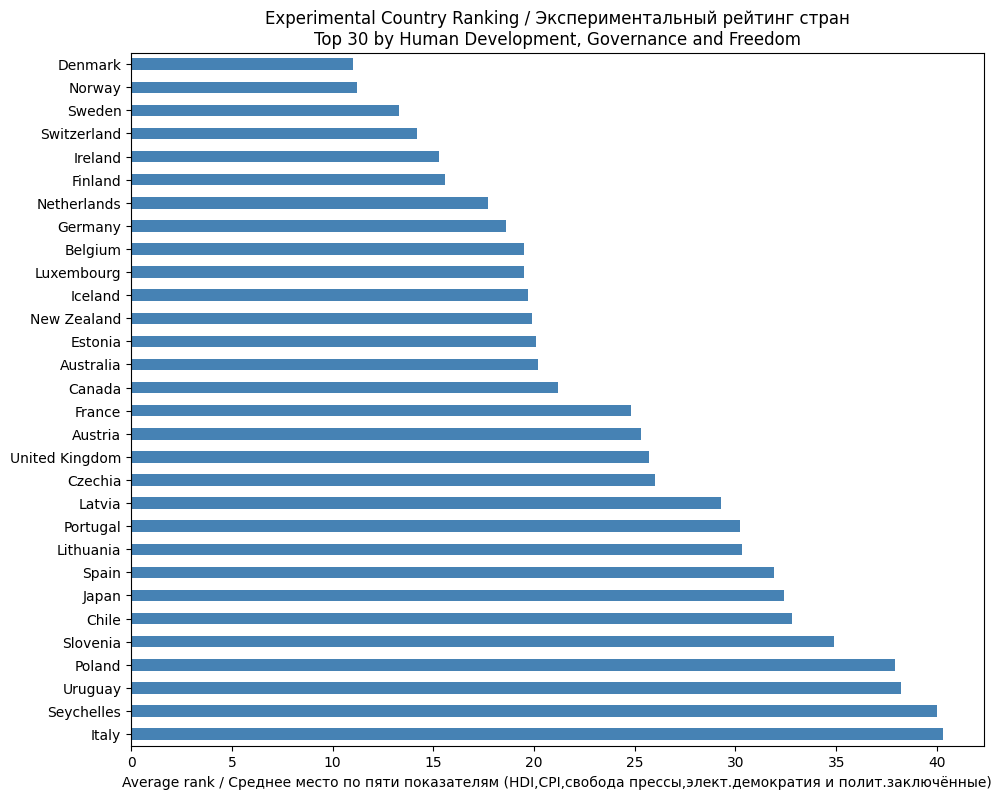

In [372]:
top30 = ranking_complete.nsmallest(30, 'overall_rank')

top30.set_index('country')['average_rank'].plot.barh(
    figsize=(11, 9),
    color='steelblue',
    width=0.5)

plt.gca().invert_yaxis()
plt.xlabel('Average rank / Среднее место по пяти показателям (HDI,CPI,свобода прессы,элект.демократия и полит.заключённые)')
plt.ylabel('')
plt.title(
    'Experimental Country Ranking / Экспериментальный рейтинг стран\n'
      'Top 30 by Human Development, Governance and Freedom')
plt.savefig('../visualizations/top30_ranking.png', dpi=200, bbox_inches='tight')
plt.show()

In [373]:
countries_final

,country_code,country,population_2025,area_sq_km,hdi_2023,gdp_per_capita_ppp_2023,electoral_democracy_2025,liberal_democracy_2025,freedom_expression_2025,cpi_2025,press_political,political_imprisonment,corruption_group
0,AFG,Afghanistan,43844111.0,652870.0,0.496,1983.81,0.069,0.018,0.022,16.0,17.78,0.0,Very high
1,AGO,Angola,39040039.0,1246700.0,0.616,8597.54,0.344,0.163,0.497,32.0,38.68,0.0,High
2,ALB,Albania,2349580.0,28750.0,0.810,20501.65,0.484,0.382,0.673,39.0,38.62,2.0,High
3,AND,Andorra,82904.0,468.0,0.913,64631.30,NaN,NaN,NaN,NaN,56.13,2.0,NaN
4,ARE,United Arab Emirates,11513149.0,98647.9,0.940,70239.83,0.104,0.077,0.063,69.0,17.23,0.0,Moderate
...,...,...,...,...,...,...,...,...,...,...,...,...,...
191,XKX,Kosovo,1576876.0,NaN,NaN,14240.20,0.631,0.457,0.766,NaN,44.61,NaN,NaN
192,YEM,"Yemen, Rep.",41773878.0,527968.0,0.470,NaN,0.127,0.043,0.219,13.0,32.01,1.0,Very high
193,ZAF,South Africa,64747319.0,1219090.0,0.741,13695.38,0.743,0.633,0.837,41.0,69.85,2.0,High
194,ZMB,Zambia,21913874.0,752612.0,0.595,3673.48,0.497,0.375,0.778,37.0,44.94,2.0,High


In [374]:
heatmap_data = (
    countries_final
    .sort_values('hdi_2023', ascending=False)
    .set_index('country'))

heatmap_columns = [
    'hdi_2023',
    'gdp_per_capita_ppp_2023',
    'cpi_2025',
    'press_political',
    'electoral_democracy_2025',
    'liberal_democracy_2025',
    'freedom_expression_2025',
    'political_imprisonment']

column_names = {
    'hdi_2023': 'HDI / Индекс развития человека',
    'gdp_per_capita_ppp_2023': 'GDP PPP / ВВП на душу населения в $ по ППС',
    'cpi_2025': 'CPI / Восприятие коррупции (выше значение — ниже воспринимаемая коррупция)',
    'press_political': 'Press / Свобода прессы',
    'electoral_democracy_2025': 'Electoral / Электоральная демократия',
    'liberal_democracy_2025': 'Liberal / Либеральная демократия',
    'freedom_expression_2025': 'Expression / Свобода выражения',
    'political_imprisonment': 'Imprisonment / Наличие политзаключённых (2-отсутствуют, 1 -мало, 0 -в наличии)'}

heatmap = (
    heatmap_data[heatmap_columns]
    .rename(columns=column_names)
    .style
    .background_gradient(cmap='YlGn', axis=0)
    .highlight_null(color='#808080')
    .format(precision=2, na_rep='—')
)

In [375]:
heatmap.to_html('../visualizations/countries_heatmap.html')

In [376]:
heatmap

,HDI / Индекс развития человека,GDP PPP / ВВП на душу населения в $ по ППС,CPI / Восприятие коррупции (выше значение — ниже воспринимаемая коррупция),Press / Свобода прессы,Electoral / Электоральная демократия,Liberal / Либеральная демократия,Expression / Свобода выражения,"Imprisonment / Наличие политзаключённых (2-отсутствуют, 1 -мало, 0 -в наличии)"
country,,,,,,,,
Iceland,0.97,69268.12,77.00,82.24,0.81,0.72,0.85,2.00
Norway,0.97,94364.96,81.00,96.22,0.89,0.85,0.95,2.00
Switzerland,0.97,85383.36,80.00,85.70,0.88,0.84,0.97,2.00
Denmark,0.96,68993.90,89.00,91.13,0.91,0.88,0.98,2.00
Germany,0.96,63140.19,77.00,84.87,0.83,0.78,0.91,2.00
Sweden,0.96,62122.51,80.00,90.07,0.89,0.85,0.95,2.00
Australia,0.96,60684.96,76.00,77.97,0.84,0.79,0.92,2.00
"Hong Kong SAR, China",0.95,64387.67,76.00,27.40,0.15,0.14,0.23,—
Netherlands,0.95,70198.95,78.00,89.95,0.83,0.77,0.91,2.00


In [377]:
heatmap_50 = (
    heatmap_data[heatmap_columns]
    .head(50)
    .rename(columns=column_names)
    .style
    .background_gradient(cmap='YlGn', axis=0)
    .highlight_null(color='#808080')
    .format(precision=2, na_rep='—')
)

plt.savefig('../visualizations/heatmap_top50.png')

<Figure size 640x480 with 0 Axes>

In [378]:
countries_final['corruption_group'] = pd.cut(countries_final['cpi_2025'],
    bins=[0, 30, 50, 70, 100],labels=['Very high', 'High', 'Moderate', 'Low'],include_lowest=True,right=False)

In [379]:
heatmap_50

,HDI / Индекс развития человека,GDP PPP / ВВП на душу населения в $ по ППС,CPI / Восприятие коррупции (выше значение — ниже воспринимаемая коррупция),Press / Свобода прессы,Electoral / Электоральная демократия,Liberal / Либеральная демократия,Expression / Свобода выражения,"Imprisonment / Наличие политзаключённых (2-отсутствуют, 1 -мало, 0 -в наличии)"
country,,,,,,,,
Iceland,0.97,69268.12,77.00,82.24,0.81,0.72,0.85,2.00
Norway,0.97,94364.96,81.00,96.22,0.89,0.85,0.95,2.00
Switzerland,0.97,85383.36,80.00,85.70,0.88,0.84,0.97,2.00
Denmark,0.96,68993.90,89.00,91.13,0.91,0.88,0.98,2.00
Germany,0.96,63140.19,77.00,84.87,0.83,0.78,0.91,2.00
Sweden,0.96,62122.51,80.00,90.07,0.89,0.85,0.95,2.00
Australia,0.96,60684.96,76.00,77.97,0.84,0.79,0.92,2.00
"Hong Kong SAR, China",0.95,64387.67,76.00,27.40,0.15,0.14,0.23,—
Netherlands,0.95,70198.95,78.00,89.95,0.83,0.77,0.91,2.00


In [380]:
from pathlib import Path

Path('visualizations').mkdir(exist_ok=True)

heatmap_50.to_html('../visualizations/heatmap_top50.html')

In [381]:
countries_final

,country_code,country,population_2025,area_sq_km,hdi_2023,gdp_per_capita_ppp_2023,electoral_democracy_2025,liberal_democracy_2025,freedom_expression_2025,cpi_2025,press_political,political_imprisonment,corruption_group
0,AFG,Afghanistan,43844111.0,652870.0,0.496,1983.81,0.069,0.018,0.022,16.0,17.78,0.0,Very high
1,AGO,Angola,39040039.0,1246700.0,0.616,8597.54,0.344,0.163,0.497,32.0,38.68,0.0,High
2,ALB,Albania,2349580.0,28750.0,0.810,20501.65,0.484,0.382,0.673,39.0,38.62,2.0,High
3,AND,Andorra,82904.0,468.0,0.913,64631.30,NaN,NaN,NaN,NaN,56.13,2.0,NaN
4,ARE,United Arab Emirates,11513149.0,98647.9,0.940,70239.83,0.104,0.077,0.063,69.0,17.23,0.0,Moderate
...,...,...,...,...,...,...,...,...,...,...,...,...,...
191,XKX,Kosovo,1576876.0,NaN,NaN,14240.20,0.631,0.457,0.766,NaN,44.61,NaN,NaN
192,YEM,"Yemen, Rep.",41773878.0,527968.0,0.470,NaN,0.127,0.043,0.219,13.0,32.01,1.0,Very high
193,ZAF,South Africa,64747319.0,1219090.0,0.741,13695.38,0.743,0.633,0.837,41.0,69.85,2.0,High
194,ZMB,Zambia,21913874.0,752612.0,0.595,3673.48,0.497,0.375,0.778,37.0,44.94,2.0,High


## Гипотеза № 3 Связь уровня восприятия коррупции (по группам) и медианного ВВП

In [382]:
result = countries_final.groupby('corruption_group').agg(median_gdp=('gdp_per_capita_ppp_2023','median'),count_gdp=('gdp_per_capita_ppp_2023','count'))
result

,median_gdp,count_gdp
corruption_group,,
Very high,5391.455,42
High,13889.950,73
Moderate,39780.940,38
Low,62631.350,20


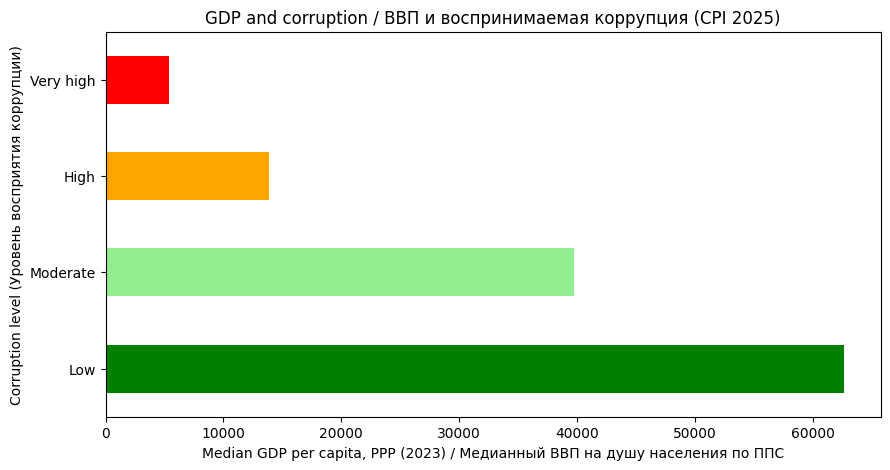

In [383]:
import matplotlib.pyplot as plt

result['median_gdp'].plot.barh(
    figsize=(10, 5),
    color=['red', 'orange', 'lightgreen', 'green']
)

plt.gca().invert_yaxis()
plt.xlabel('Median GDP per capita, PPP (2023) / Медианный ВВП на душу населения по ППС')
plt.ylabel('Corruption level (Уровень восприятия коррупции)')
plt.title('GDP and corruption / ВВП и воспринимаемая коррупция (CPI 2025)')
plt.savefig('../visualizations/gdp_corruption.png', dpi=200, bbox_inches='tight')
plt.show()


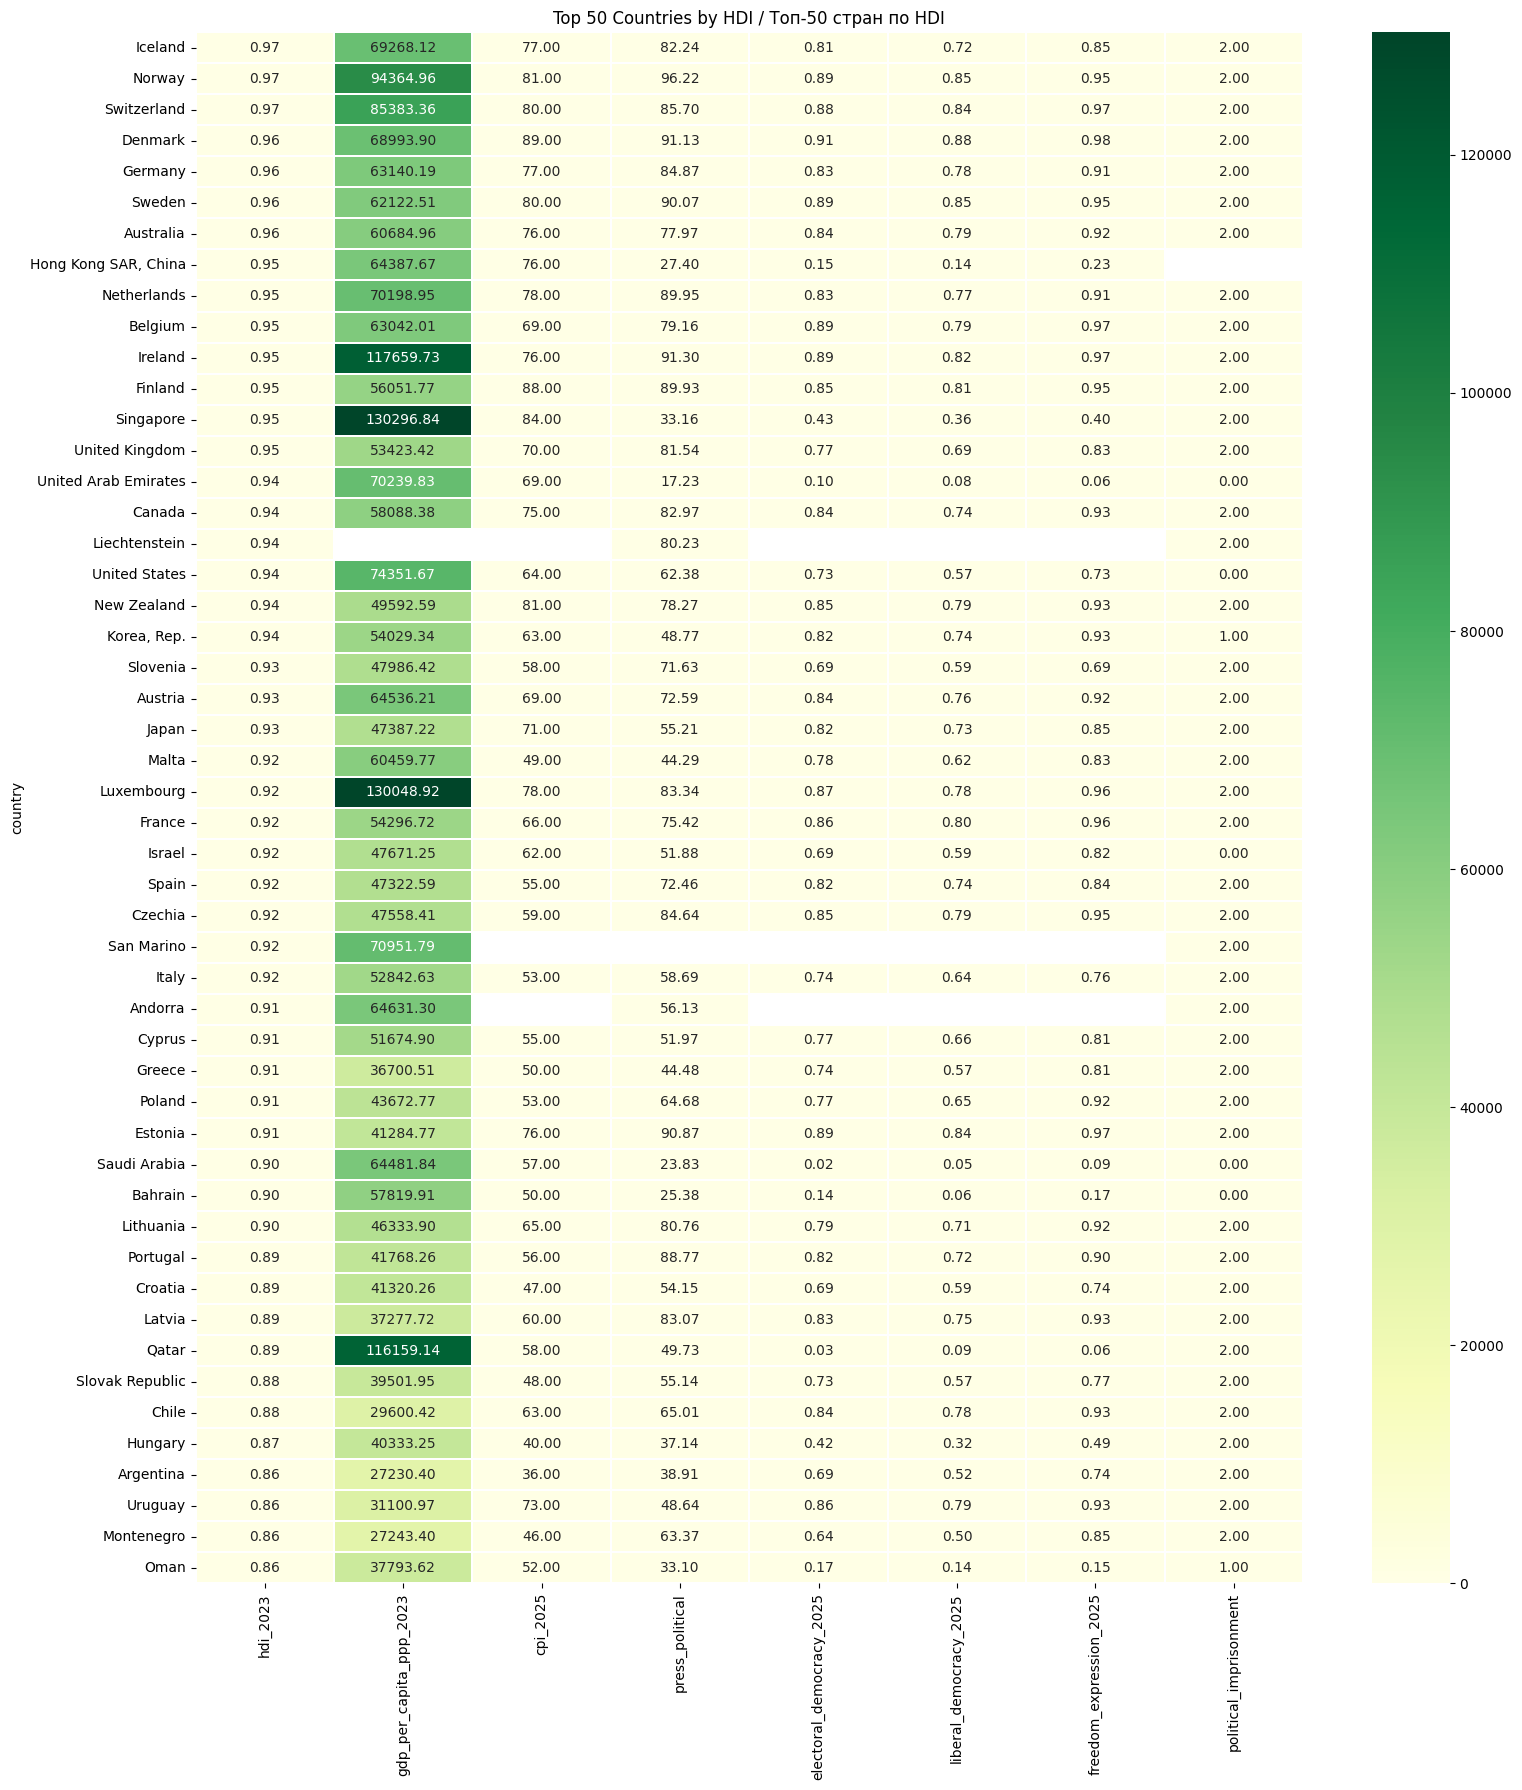

In [384]:
import matplotlib.pyplot as plt
import seaborn as sns

heatmap_50 = heatmap_data[heatmap_columns].head(50)

plt.figure(figsize=(16, 18))

sns.heatmap(
    heatmap_50,
    cmap='YlGn',
    annot=True,
    fmt='.2f',
    linewidths=0.3
)

plt.title('Top 50 Countries by HDI / Топ-50 стран по HDI')
plt.tight_layout()
plt.savefig('../visualizations/heatmap_top50.png', dpi=200, bbox_inches='tight')
plt.show()

In [385]:
filtered_country = countries_final[countries_final['country'] == 'India']
filtered_country

,country_code,country,population_2025,area_sq_km,hdi_2023,gdp_per_capita_ppp_2023,electoral_democracy_2025,liberal_democracy_2025,freedom_expression_2025,cpi_2025,press_political,political_imprisonment,corruption_group
78,IND,India,1.463866e+09,3287263.0,0.685,8870.55,0.377,0.26,0.458,39.0,24.3,1.0,High
